In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/x-ray-lung-diseases-images-9-classes/04 Doenças Pulmonares Obstrutivas (Enfisema, Broncopneumonia, Bronquiectasia, Embolia)/04 (186).jpeg
/kaggle/input/x-ray-lung-diseases-images-9-classes/04 Doenças Pulmonares Obstrutivas (Enfisema, Broncopneumonia, Bronquiectasia, Embolia)/04 (152).jpeg
/kaggle/input/x-ray-lung-diseases-images-9-classes/04 Doenças Pulmonares Obstrutivas (Enfisema, Broncopneumonia, Bronquiectasia, Embolia)/04 (411).jpeg
/kaggle/input/x-ray-lung-diseases-images-9-classes/04 Doenças Pulmonares Obstrutivas (Enfisema, Broncopneumonia, Bronquiectasia, Embolia)/04 (244).jpeg
/kaggle/input/x-ray-lung-diseases-images-9-classes/04 Doenças Pulmonares Obstrutivas (Enfisema, Broncopneumonia, Bronquiectasia, Embolia)/04 (450).jpeg
/kaggle/input/x-ray-lung-diseases-images-9-classes/04 Doenças Pulmonares Obstrutivas (Enfisema, Broncopneumonia, Bronquiectasia, Embolia)/04 (124).jpeg
/kaggle/input/x-ray-lung-diseases-images-9-classes/04 Doenças Pulmonares Obstrutivas (En

In [2]:
import os
import cv2
import math
import torch
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm
from torch import nn
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import models, transforms
from sklearn.metrics import classification_report, confusion_matrix

In [3]:
data_dir = "/kaggle/input/x-ray-lung-diseases-images-9-classes"
print(os.listdir(data_dir))  # This should show the 9 class folders

['04 Doenças Pulmonares Obstrutivas (Enfisema, Broncopneumonia, Bronquiectasia, Embolia)', '02 Maior Densidade (Derrame Pleural, Consolidação Atelectasica, Hidrotorax, Empiema)', '03 Menor Densidade (Pneumotorax, Pneumomediastino, Pneumoperitonio)', '08 Alterações do Tórax (Atelectasias, Malformações, Agenesia, Hipoplasias)', '06 Lesões Encapsuladas (Abscessos, Nódulos, Cistos, Massas Tumorais, Metastases)', '05 Doenças Infecciosas Degenerativas (Tuberculose, Sarcoidose, Proteinose, Fibrose)', '00 Anatomia Normal', '07 Alterações de Mediastino (Pericardite, Malformações Arteriovenosas, Linfonodomegalias)', '01 Processos Inflamatórios Pulmonares (Pneumonia)']


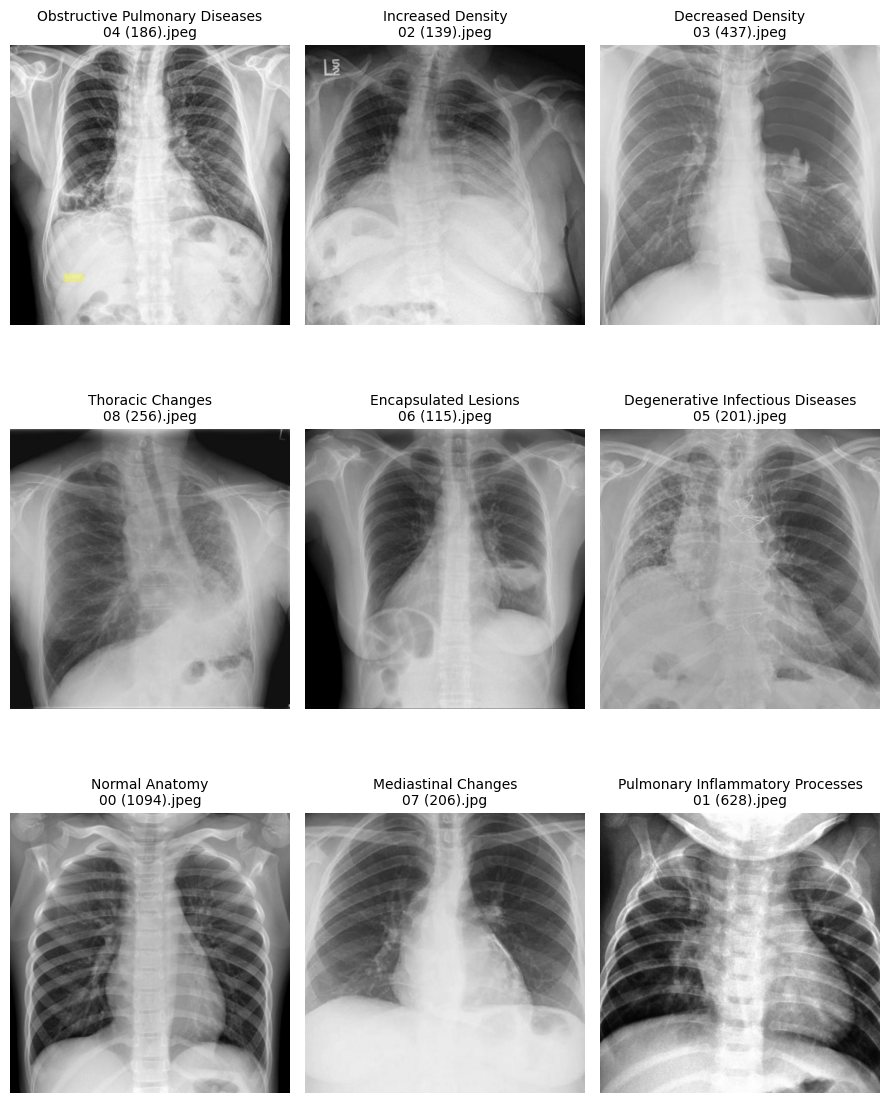

In [4]:
# Define the dataset path
dataset_path = "/kaggle/input/x-ray-lung-diseases-images-9-classes"  # Change this to your dataset path

# Define the mapping of folder names to new class names
class_name_mapping = {
    "00 Anatomia Normal": "Normal Anatomy",
    "01 Processos Inflamatórios Pulmonares (Pneumonia)": "Pulmonary Inflammatory Processes",
    "02 Maior Densidade (Derrame Pleural, Consolidação Atelectasica, Hidrotorax, Empiema)": "Increased Density",
    "03 Menor Densidade (Pneumotorax, Pneumomediastino, Pneumoperitonio)": "Decreased Density",
    "04 Doenças Pulmonares Obstrutivas (Enfisema, Broncopneumonia, Bronquiectasia, Embolia)": "Obstructive Pulmonary Diseases",
    "05 Doenças Infecciosas Degenerativas (Tuberculose, Sarcoidose, Proteinose, Fibrose)": "Degenerative Infectious Diseases",
    "06 Lesões Encapsuladas (Abscessos, Nódulos, Cistos, Massas Tumorais, Metastases)": "Encapsulated Lesions",
    "07 Alterações de Mediastino (Pericardite, Malformações Arteriovenosas, Linfonodomegalias)": "Mediastinal Changes",
    "08 Alterações do Tórax (Atelectasias, Malformações, Agenesia, Hipoplasias)": "Thoracic Changes"
}

# Get class folders (filter only the mapped ones)
classes = [cls for cls in os.listdir(dataset_path) if cls in class_name_mapping]

# Determine grid size
cols = 3  # Number of images per row
rows = math.ceil(len(classes) / cols)

# Set up the figure for display
fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 4))
axes = axes.flatten()

for i, class_folder in enumerate(classes):
    class_path = os.path.join(dataset_path, class_folder)
    class_name = class_name_mapping[class_folder]  # Get the new name
    image_files = [f for f in os.listdir(class_path) if f.endswith(('.jpg', '.jpeg'))]
    
    if image_files:
        img_name = image_files[0]  # Select only one image per class
        img_path = os.path.join(class_path, img_name)
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB for correct color display

        axes[i].imshow(img)
        axes[i].axis("off")
        axes[i].set_title(f"{class_name}\n{img_name}", fontsize=10)

# Hide unused subplots
for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.savefig("lung_disease_samples.png", dpi=300)
plt.show()


**EDA**

In [5]:
# 1. Count number of images per class (improved version)
import collections

class_counts = {}
image_shapes = []
color_modes = collections.defaultdict(int)

for class_folder in classes:
    folder_path = os.path.join(dataset_path, class_folder)
    
    # include png files too
    image_files = [f for f in os.listdir(folder_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    class_name = class_name_mapping[class_folder]
    
    class_counts[class_name] = len(image_files)
    
    # Sample 5 images for checking shapes and color modes
    for img_file in image_files[:5]:
        img_path = os.path.join(folder_path, img_file)
        try:
            img = Image.open(img_path)
            image_shapes.append(img.size)  # (width, height)
            color_modes[img.mode] += 1
            img.close()
        except Exception as e:
            print(f"Could not process image {img_path}: {e}")


/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


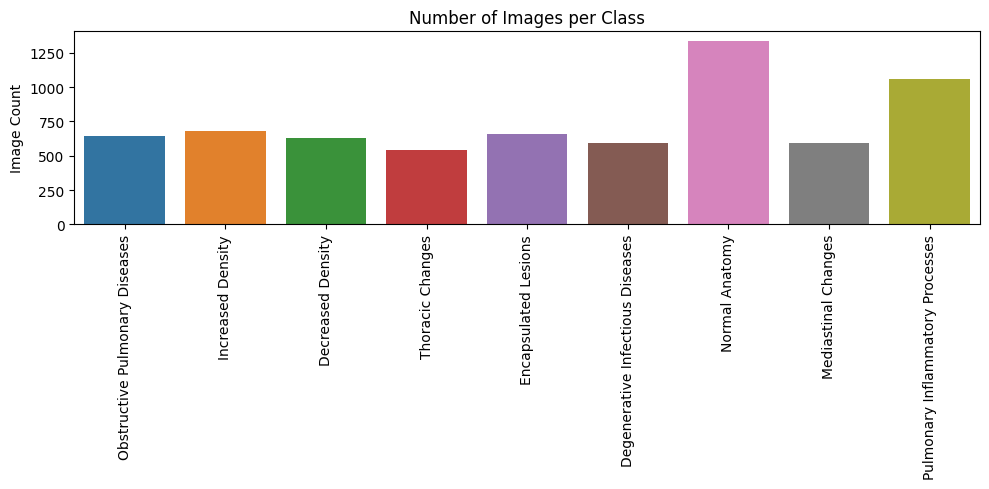

In [6]:
# 2. Plot class distribution
plt.figure(figsize=(10, 5))
sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()))
plt.xticks(rotation=90)
plt.title("Number of Images per Class")
plt.ylabel("Image Count")
plt.tight_layout()
plt.show()

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


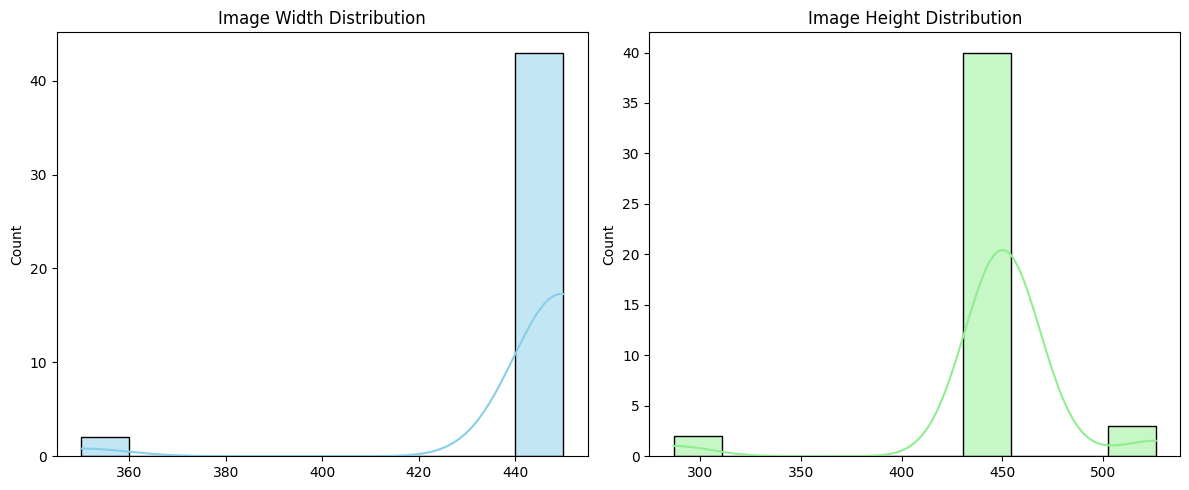

In [7]:
# 3. Image size distribution
widths, heights = zip(*image_shapes)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(widths, bins=10, kde=True, color="skyblue")
plt.title("Image Width Distribution")

plt.subplot(1, 2, 2)
sns.histplot(heights, bins=10, kde=True, color="lightgreen")
plt.title("Image Height Distribution")
plt.tight_layout()
plt.show()

In [8]:
# 4. Color mode summary
print("Color Modes in Sampled Images:")
for mode, count in color_modes.items():
    print(f"- {mode}: {count} images")

Color Modes in Sampled Images:
- RGB: 22 images
- L: 22 images
- RGBA: 1 images


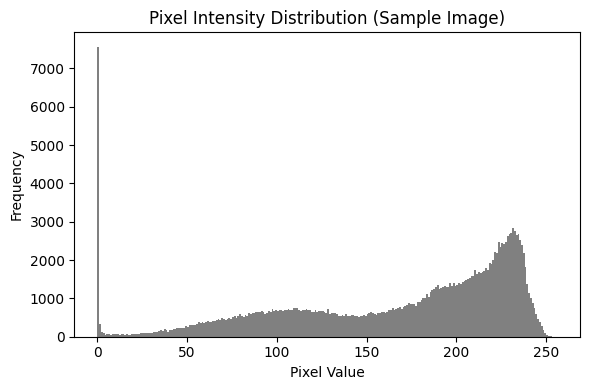

In [9]:
# 5. Pixel intensity histogram (grayscale example)
# Take a sample image and plot its pixel histogram
sample_img_path = os.path.join(dataset_path, classes[0], os.listdir(os.path.join(dataset_path, classes[0]))[0])
sample_img = cv2.imread(sample_img_path, cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(6, 4))
plt.hist(sample_img.ravel(), bins=256, range=[0, 256], color='gray')
plt.title("Pixel Intensity Distribution (Sample Image)")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


**DATA PreProcessing**

In [10]:
import torch.nn as nn
from torchvision import models, transforms
from torch.utils.data import DataLoader, Dataset, random_split
import os, cv2
from PIL import Image, ImageEnhance
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from tqdm import tqdm
import random

In [11]:
# ---------------------------
# Advanced Dataset + Preprocessing
# ---------------------------

class PreprocessedLungXrayDataset(Dataset):
    def __init__(self, root_dir, transform=None, enhance=True):
        self.root_dir = root_dir
        self.transform = transform
        self.enhance = enhance
        self.image_paths = []
        self.labels = []
        self.class_names = sorted(os.listdir(root_dir))

        for idx, class_folder in enumerate(self.class_names):
            full_path = os.path.join(root_dir, class_folder)
            for img_file in os.listdir(full_path):
                if img_file.lower().endswith(('.jpg', '.jpeg', '.png')):
                    self.image_paths.append(os.path.join(full_path, img_file))
                    self.labels.append(idx)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label = self.labels[idx]

        # Load as grayscale
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

        if self.enhance:
            # CLAHE for contrast enhancement
            clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
            img = clahe.apply(img)

            # Apply light sharpening
            kernel = np.array([[0, -1, 0], 
                               [-1, 5,-1], 
                               [0, -1, 0]])
            img = cv2.filter2D(img, -1, kernel)

            # Add slight Gaussian noise
            noise = np.random.normal(0, 5, img.shape).astype(np.uint8)
            img = cv2.add(img, noise)

            # Clip pixel values to [0, 255] just in case
            img = np.clip(img, 0, 255)

        img = Image.fromarray(img)

        if self.transform:
            img = self.transform(img)

        return img, label

# ---------------------------
# Advanced Augmentation Pipeline
# ---------------------------

transform_augmented = transforms.Compose([
    transforms.Grayscale(num_output_channels=3), 
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(degrees=15),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), shear=5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.RandomResizedCrop(size=224, scale=(0.8, 1.0), ratio=(0.9, 1.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])


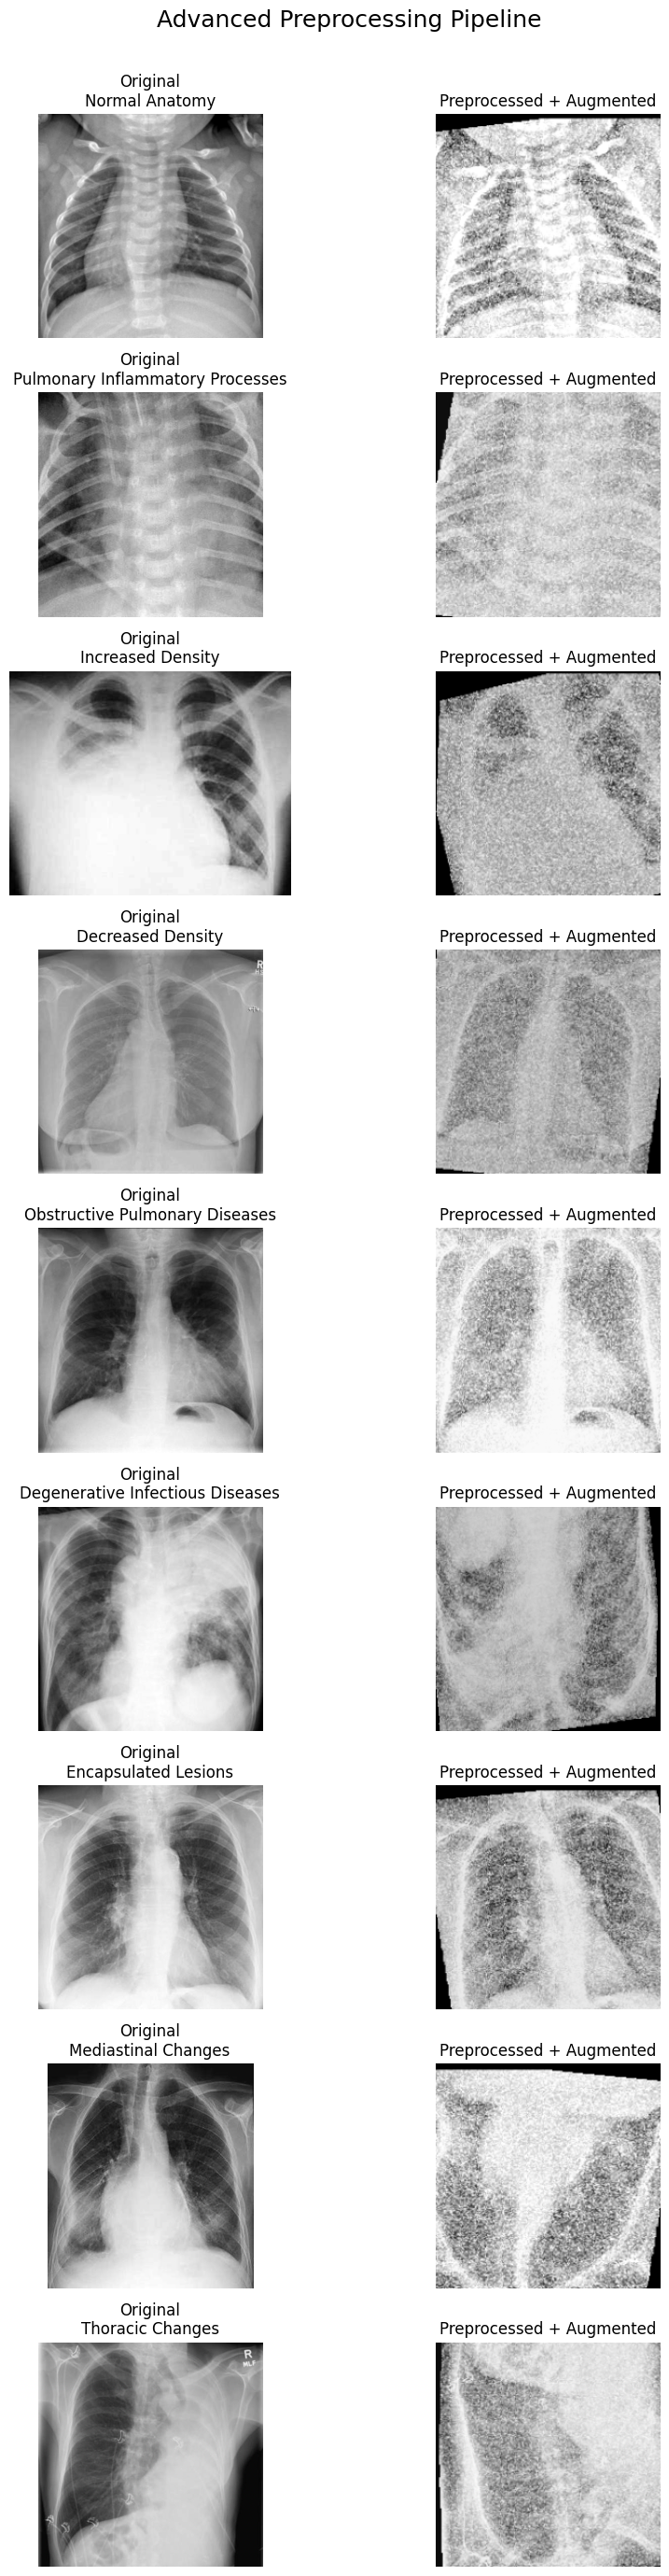

In [30]:
# Load full dataset with advanced preprocessing
data_dir = "/kaggle/input/x-ray-lung-diseases-images-9-classes"
full_dataset = PreprocessedLungXrayDataset(root_dir=data_dir, transform=transform_augmented, enhance=True)

from torch.utils.data import DataLoader, WeightedRandomSampler
import torch

# ---------------------------
# Visualize sample images after advanced preprocessing
# ---------------------------

sample_paths = []
sample_labels = []

class_dirs = sorted(os.listdir(data_dir))

for class_folder in class_dirs:
    if class_folder not in class_name_mapping:
        continue
    class_path = os.path.join(data_dir, class_folder)
    image_files = [f for f in os.listdir(class_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if image_files:
        img_file = random.choice(image_files)
        sample_paths.append(os.path.join(class_path, img_file))
        sample_labels.append(class_folder)

fig, axes = plt.subplots(len(sample_paths), 2, figsize=(10, len(sample_paths) * 3))

for i, img_path in enumerate(sample_paths):
    # --- Original ---
    raw_img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

    # --- Apply full enhancement manually for visualization ---
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced_img = clahe.apply(raw_img)

    kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
    sharpened_img = cv2.filter2D(enhanced_img, -1, kernel)
    noise = np.random.normal(0, 5, sharpened_img.shape).astype(np.uint8)
    final_img = cv2.add(sharpened_img, noise)
    final_img = np.clip(final_img, 0, 255)

    img_pil = Image.fromarray(final_img)
    transformed = transform_augmented(img_pil)
    transformed_np = transformed.permute(1, 2, 0).numpy()

    axes[i, 0].imshow(raw_img, cmap='gray')
    axes[i, 0].set_title(f"Original\n{class_name_mapping.get(sample_labels[i], sample_labels[i])}")
    axes[i, 0].axis('off')

    axes[i, 1].imshow((transformed_np * 0.5 + 0.5).clip(0, 1))  # unnormalize for display
    axes[i, 1].set_title("Preprocessed + Augmented")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.suptitle("Advanced Preprocessing Pipeline", fontsize=18, y=1.02)
plt.savefig("BEFORE & AFTER PREPROCESSING", dpi=300)
plt.show()

**Train-Test-Val**

In [31]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import transforms, models
from tqdm import tqdm
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import copy

In [32]:
transform_validation = transforms.Compose([
    transforms.Grayscale(num_output_channels=3), 
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])


In [33]:
# Split dataset
torch.manual_seed(42)
total_size = len(full_dataset)
train_size = int(0.7 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(full_dataset, [train_size, val_size, test_size])

# Apply transforms to val/test
val_dataset.dataset.transform = transform_validation
test_dataset.dataset.transform = transform_validation

# Dataloaders
#train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)


<ipython-input-34-b797a4bae37b>:43: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


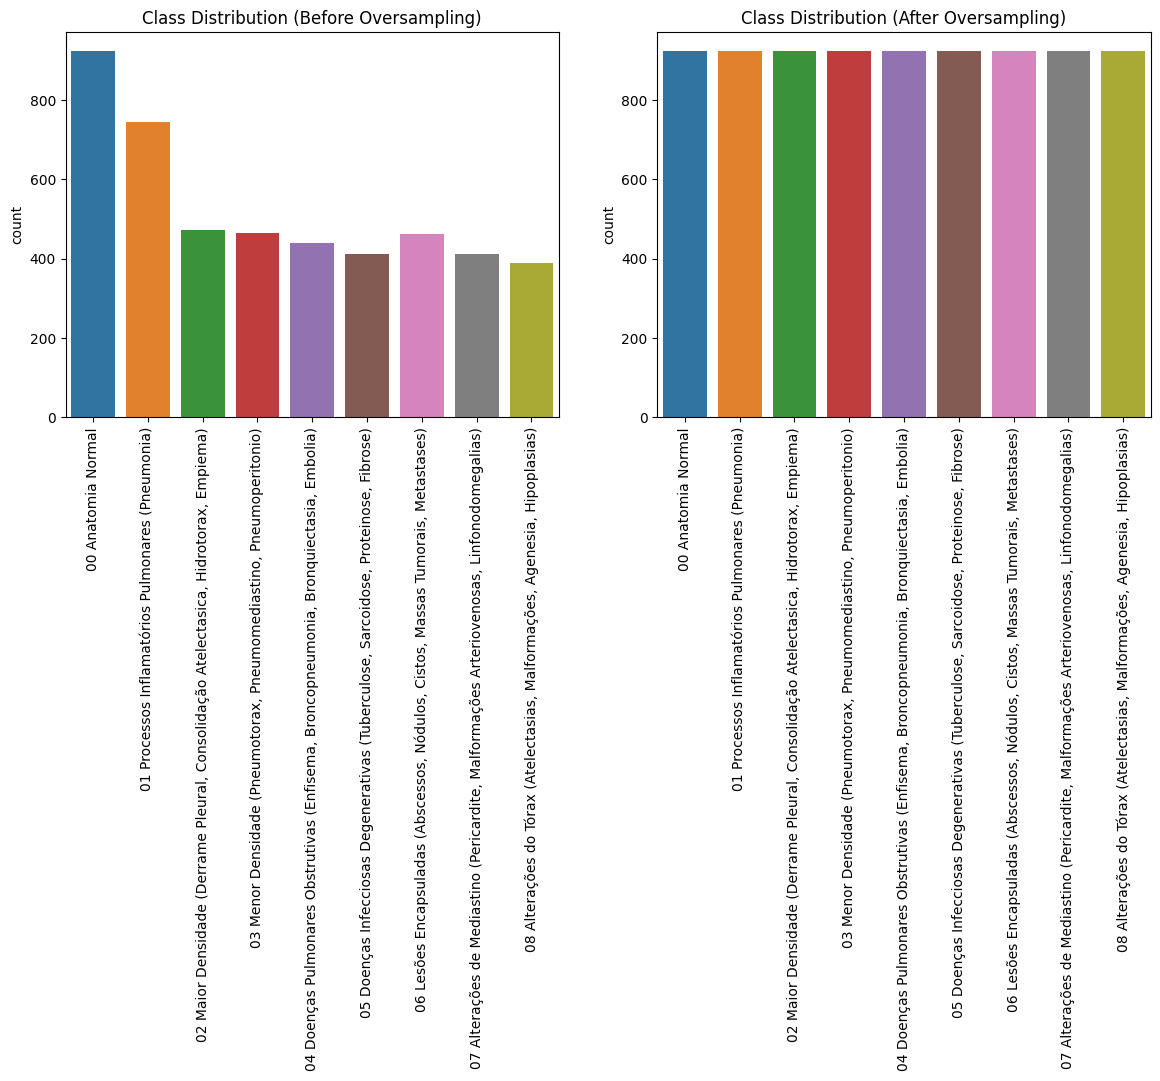

In [34]:
from torch.utils.data import ConcatDataset, Subset
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def oversample_dataset(dataset, target_count=None):
    labels = [dataset[i][1] for i in range(len(dataset))]
    class_counts = np.bincount(labels)
    max_count = target_count or max(class_counts)

    subsets = []
    for class_idx, count in enumerate(class_counts):
        indices = [i for i, l in enumerate(labels) if l == class_idx]
        oversampled_indices = np.random.choice(indices, max_count, replace=True)
        subsets.append(Subset(dataset, oversampled_indices))

    return ConcatDataset(subsets), max_count, class_counts

# Oversample the training dataset
train_dataset_balanced, max_count, class_counts_before = oversample_dataset(train_dataset)

# New dataloader
train_loader = DataLoader(train_dataset_balanced, batch_size=32, shuffle=True)

# ---- Visualization ----
labels_before = [train_dataset[i][1] for i in range(len(train_dataset))]
labels_after = [train_dataset_balanced[i][1] for i in range(len(train_dataset_balanced))]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Before oversampling
sns.countplot(x=labels_before, ax=axes[0], order=range(len(full_dataset.class_names)))
axes[0].set_title("Class Distribution (Before Oversampling)")
axes[0].set_xticks(range(len(full_dataset.class_names)))
axes[0].set_xticklabels(full_dataset.class_names, rotation=90)

# After oversampling
sns.countplot(x=labels_after, ax=axes[1], order=range(len(full_dataset.class_names)))
axes[1].set_title("Class Distribution (After Oversampling)")
axes[1].set_xticks(range(len(full_dataset.class_names)))
axes[1].set_xticklabels(full_dataset.class_names, rotation=90)

plt.tight_layout()
plt.show()


**Feature Extraction**

TEST MODEL (VGG-16)

In [35]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [36]:
class MultiBackboneFeatureExtractor(nn.Module):
    def __init__(self, backbone='vgg16'):
        super().__init__()
        self.backbone_name = backbone.lower()

        if self.backbone_name == 'vgg16':
            model = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
            self.features = model.features
            self.pooling = model.avgpool
            self.flatten = nn.Flatten()
            self.fc = nn.Sequential(*list(model.classifier.children())[:-1])

        elif self.backbone_name == 'resnet50':
            model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
            self.features = nn.Sequential(*list(model.children())[:-1])
            self.flatten = nn.Flatten()
            self.fc = nn.Identity()

        elif self.backbone_name == 'densenet121':
            model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
            self.features = model.features
            self.pooling = nn.AdaptiveAvgPool2d((1, 1))
            self.flatten = nn.Flatten()
            self.fc = nn.Identity()

        else:
            raise ValueError(f"Backbone '{backbone}' not supported")

        for param in self.parameters():
            param.requires_grad = False

    def forward(self, x):
        x = self.features(x)
        if self.backbone_name in ['vgg16', 'densenet121']:
            x = self.pooling(x)
        x = self.flatten(x)
        x = self.fc(x)
        return x


In [37]:
def extract_features(loader, extractor, device):
    extractor.eval()
    features_list, labels_list = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            features = extractor(imgs)
            features_list.append(features.cpu())
            labels_list.append(labels)
    return torch.cat(features_list), torch.cat(labels_list)


In [38]:
class FCNNClassifier(nn.Module):
    def __init__(self, input_dim, num_classes=9):
        super().__init__()
        self.classifier = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.classifier(x)


In [39]:
def train_model(classifier, X_train, y_train, X_val, y_val, device, epochs=300):
    classifier.to(device)
    loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)

    X_train, y_train = X_train.to(device), y_train.to(device)
    X_val, y_val = X_val.to(device), y_val.to(device)

    for epoch in range(epochs):
        classifier.train()
        optimizer.zero_grad()
        outputs = classifier(X_train)
        loss = loss_fn(outputs, y_train)
        loss.backward()
        optimizer.step()

        classifier.eval()
        with torch.no_grad():
            val_outputs = classifier(X_val)
            val_loss = loss_fn(val_outputs, y_val)
            val_acc = (val_outputs.argmax(1) == y_val).float().mean()

        scheduler.step(val_loss)
        print(f"Epoch {epoch+1}/{epochs} | Loss: {loss.item():.4f} | Val Loss: {val_loss.item():.4f} | Val Acc: {val_acc:.4f}")

    return classifier


In [40]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

def evaluate_model(classifier, X_test, y_test, device, class_names):
    classifier.eval()
    X_test, y_test = X_test.to(device), y_test.to(device)
    with torch.no_grad():
        outputs = classifier(X_test)
        preds = outputs.argmax(1)

    print("\nClassification Report:")
    print(classification_report(y_test.cpu(), preds.cpu(), target_names=class_names))

    cm = confusion_matrix(y_test.cpu(), preds.cpu())
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.title("Confusion Matrix")
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.show()


In [41]:
# VGG16 Example
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

extractor_vgg = MultiBackboneFeatureExtractor(backbone='vgg16').to(device)
X_train_vgg, y_train_vgg = extract_features(train_loader, extractor_vgg, device)
X_val_vgg, y_val_vgg = extract_features(val_loader, extractor_vgg, device)
X_test_vgg, y_test_vgg = extract_features(test_loader, extractor_vgg, device)

classifier_vgg = FCNNClassifier(input_dim=4096)
classifier_vgg = train_model(classifier_vgg, X_train_vgg, y_train_vgg, X_val_vgg, y_val_vgg, device)

Epoch 1/300 | Loss: 2.2811 | Val Loss: 2.1828 | Val Acc: 0.1909
Epoch 2/300 | Loss: 2.1335 | Val Loss: 2.1743 | Val Acc: 0.2196
Epoch 3/300 | Loss: 2.0092 | Val Loss: 2.1639 | Val Acc: 0.2493
Epoch 4/300 | Loss: 1.9294 | Val Loss: 2.1519 | Val Acc: 0.2888
Epoch 5/300 | Loss: 1.8540 | Val Loss: 2.1386 | Val Acc: 0.3254
Epoch 6/300 | Loss: 1.7995 | Val Loss: 2.1238 | Val Acc: 0.3591
Epoch 7/300 | Loss: 1.7443 | Val Loss: 2.1076 | Val Acc: 0.3927
Epoch 8/300 | Loss: 1.6996 | Val Loss: 2.0901 | Val Acc: 0.4322
Epoch 9/300 | Loss: 1.6562 | Val Loss: 2.0712 | Val Acc: 0.4441
Epoch 10/300 | Loss: 1.6220 | Val Loss: 2.0511 | Val Acc: 0.4550
Epoch 11/300 | Loss: 1.5868 | Val Loss: 2.0297 | Val Acc: 0.4797
Epoch 12/300 | Loss: 1.5541 | Val Loss: 2.0071 | Val Acc: 0.4936
Epoch 13/300 | Loss: 1.5170 | Val Loss: 1.9832 | Val Acc: 0.5153
Epoch 14/300 | Loss: 1.4899 | Val Loss: 1.9579 | Val Acc: 0.5341
Epoch 15/300 | Loss: 1.4641 | Val Loss: 1.9313 | Val Acc: 0.5460
Epoch 16/300 | Loss: 1.4423 | Val 


Classification Report:
                                                                                           precision    recall  f1-score   support

                                                                       00 Anatomia Normal       0.90      0.87      0.89       205
                                        01 Processos Inflamatórios Pulmonares (Pneumonia)       0.84      0.76      0.80       156
     02 Maior Densidade (Derrame Pleural, Consolidação Atelectasica, Hidrotorax, Empiema)       0.92      0.96      0.94        98
                      03 Menor Densidade (Pneumotorax, Pneumomediastino, Pneumoperitonio)       0.91      1.00      0.95        83
   04 Doenças Pulmonares Obstrutivas (Enfisema, Broncopneumonia, Bronquiectasia, Embolia)       0.97      0.90      0.93        99
      05 Doenças Infecciosas Degenerativas (Tuberculose, Sarcoidose, Proteinose, Fibrose)       0.86      0.93      0.89        85
         06 Lesões Encapsuladas (Abscessos, Nódulos, Cisto

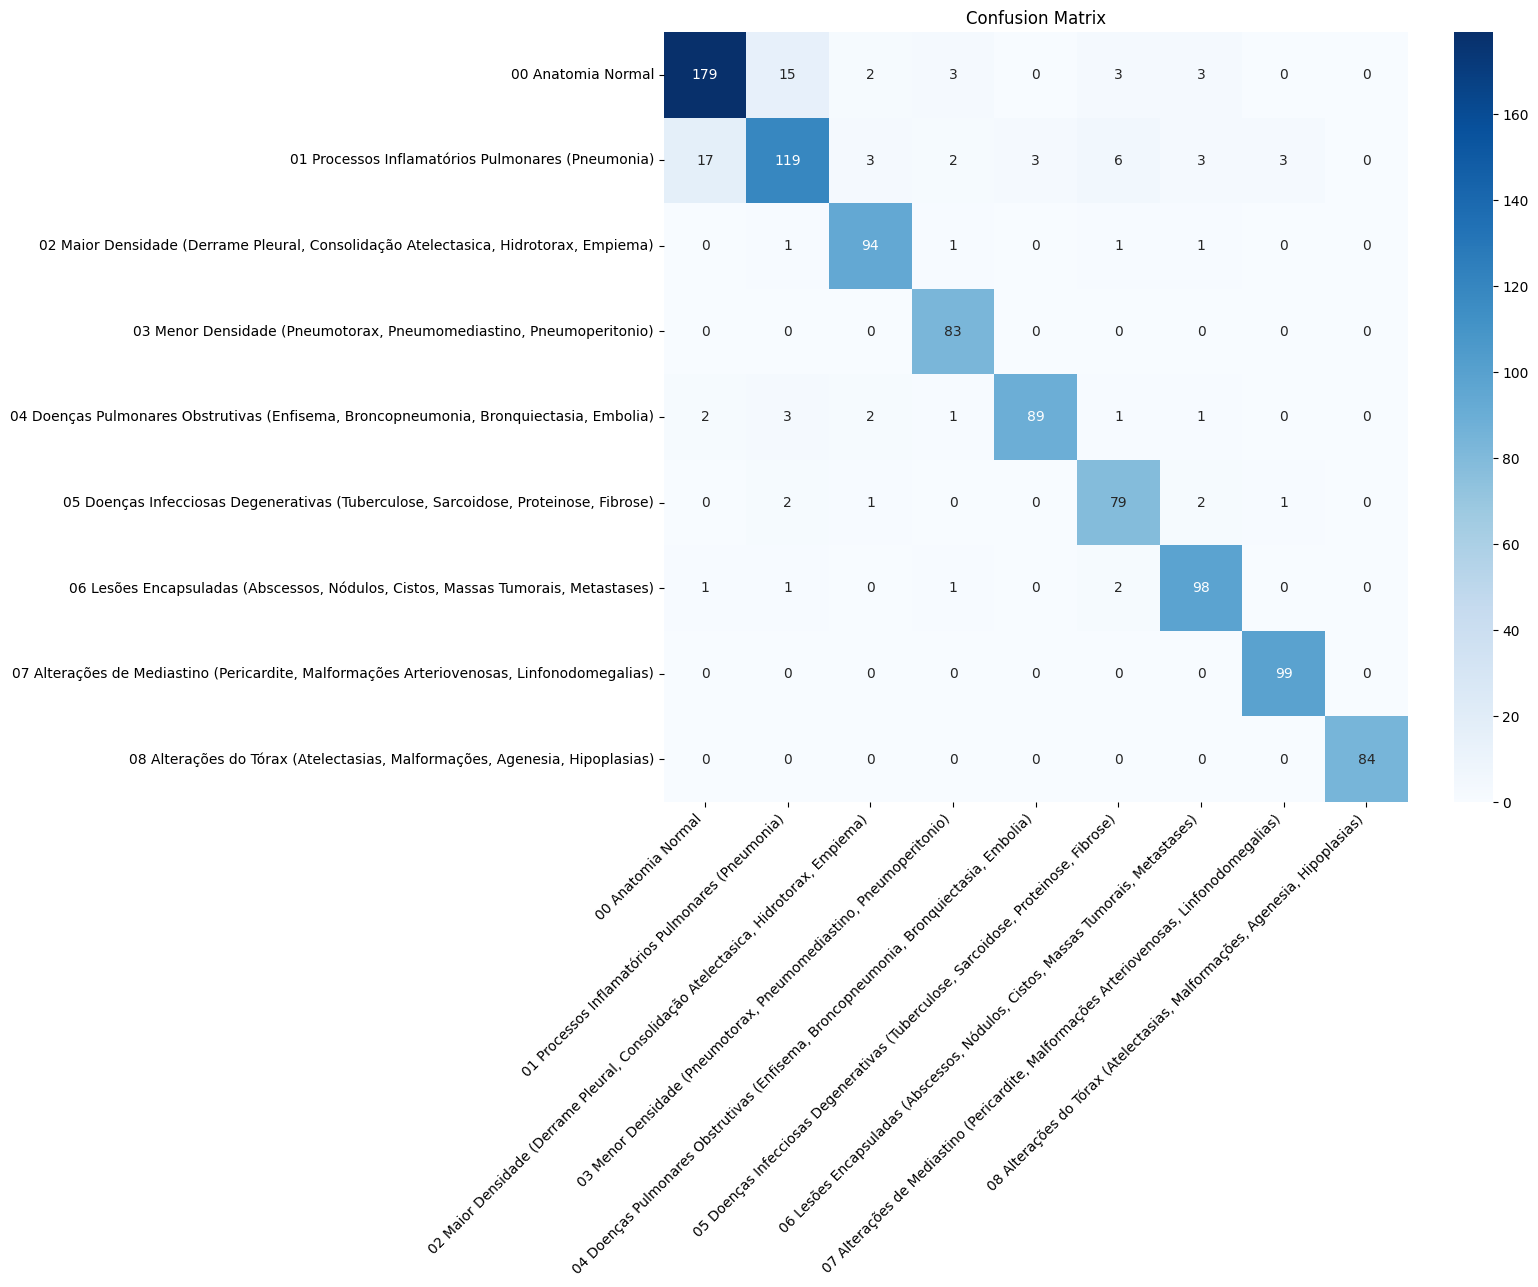

In [42]:
evaluate_model(classifier_vgg, X_test_vgg, y_test_vgg, device, class_names=full_dataset.class_names)

In [43]:
# ResNet50 Example
extractor_resnet = MultiBackboneFeatureExtractor(backbone='resnet50').to(device)
X_train_resnet, y_train_resnet = extract_features(train_loader, extractor_resnet, device)
X_val_resnet, y_val_resnet = extract_features(val_loader, extractor_resnet, device)
X_test_resnet, y_test_resnet = extract_features(test_loader, extractor_resnet, device)

classifier_resnet = FCNNClassifier(input_dim=2048)
classifier_resnet = train_model(classifier_resnet, X_train_resnet, y_train_resnet, X_val_resnet, y_val_resnet, device)

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 203MB/s]


Epoch 1/300 | Loss: 2.2841 | Val Loss: 2.1751 | Val Acc: 0.2502
Epoch 2/300 | Loss: 2.1560 | Val Loss: 2.1648 | Val Acc: 0.2750
Epoch 3/300 | Loss: 2.0479 | Val Loss: 2.1523 | Val Acc: 0.3086
Epoch 4/300 | Loss: 1.9584 | Val Loss: 2.1381 | Val Acc: 0.3541
Epoch 5/300 | Loss: 1.8891 | Val Loss: 2.1229 | Val Acc: 0.3788
Epoch 6/300 | Loss: 1.8333 | Val Loss: 2.1073 | Val Acc: 0.4045
Epoch 7/300 | Loss: 1.7855 | Val Loss: 2.0911 | Val Acc: 0.4105
Epoch 8/300 | Loss: 1.7396 | Val Loss: 2.0743 | Val Acc: 0.4233
Epoch 9/300 | Loss: 1.7032 | Val Loss: 2.0570 | Val Acc: 0.4283
Epoch 10/300 | Loss: 1.6636 | Val Loss: 2.0387 | Val Acc: 0.4313
Epoch 11/300 | Loss: 1.6329 | Val Loss: 2.0199 | Val Acc: 0.4441
Epoch 12/300 | Loss: 1.6035 | Val Loss: 2.0007 | Val Acc: 0.4540
Epoch 13/300 | Loss: 1.5686 | Val Loss: 1.9809 | Val Acc: 0.4629
Epoch 14/300 | Loss: 1.5445 | Val Loss: 1.9605 | Val Acc: 0.4817
Epoch 15/300 | Loss: 1.5234 | Val Loss: 1.9395 | Val Acc: 0.5025
Epoch 16/300 | Loss: 1.4943 | Val 


Classification Report:
                                                                                           precision    recall  f1-score   support

                                                                       00 Anatomia Normal       0.93      0.93      0.93       205
                                        01 Processos Inflamatórios Pulmonares (Pneumonia)       0.89      0.76      0.82       156
     02 Maior Densidade (Derrame Pleural, Consolidação Atelectasica, Hidrotorax, Empiema)       0.99      1.00      0.99        98
                      03 Menor Densidade (Pneumotorax, Pneumomediastino, Pneumoperitonio)       0.94      0.98      0.96        83
   04 Doenças Pulmonares Obstrutivas (Enfisema, Broncopneumonia, Bronquiectasia, Embolia)       0.91      0.91      0.91        99
      05 Doenças Infecciosas Degenerativas (Tuberculose, Sarcoidose, Proteinose, Fibrose)       0.92      0.93      0.92        85
         06 Lesões Encapsuladas (Abscessos, Nódulos, Cisto

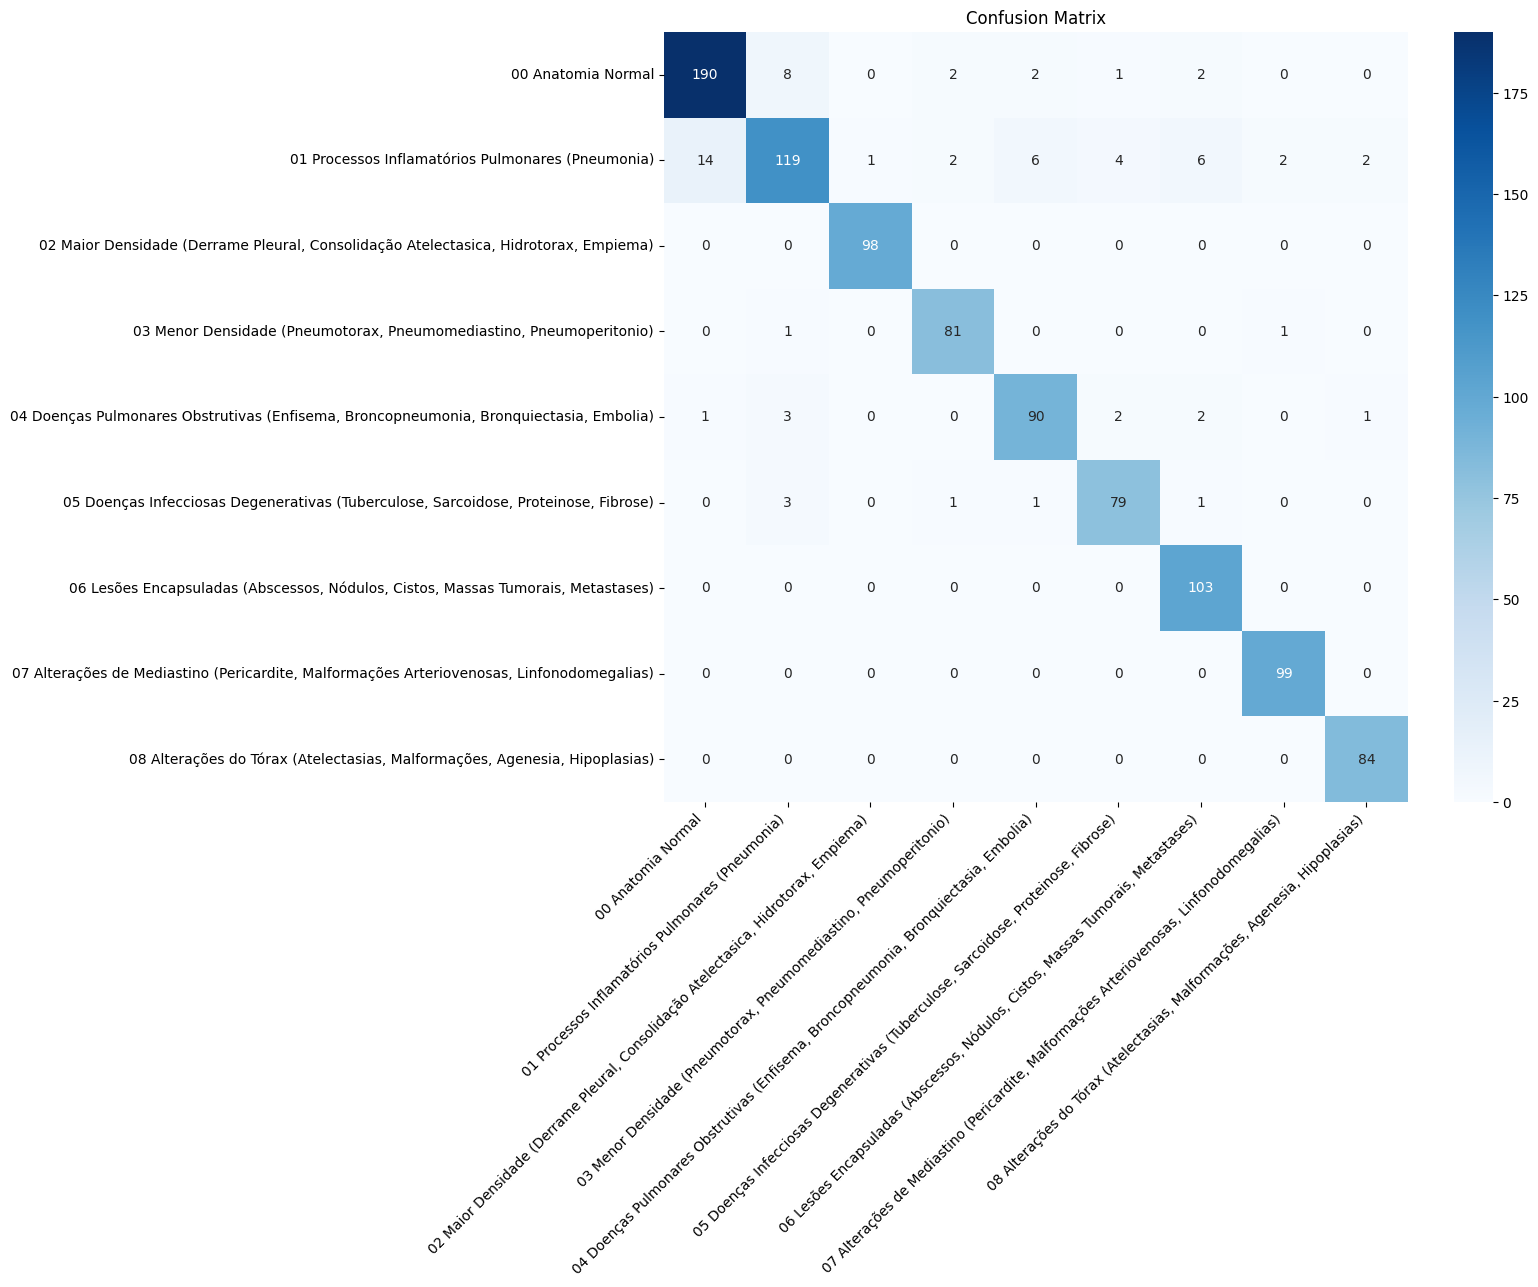

In [44]:
evaluate_model(classifier_resnet, X_test_resnet, y_test_resnet, device, class_names=full_dataset.class_names)

In [45]:
# DenseNet121 Example
extractor_densenet = MultiBackboneFeatureExtractor(backbone='densenet121').to(device)
X_train_dense, y_train_dense = extract_features(train_loader, extractor_densenet, device)
X_val_dense, y_val_dense = extract_features(val_loader, extractor_densenet, device)
X_test_dense, y_test_dense = extract_features(test_loader, extractor_densenet, device)

classifier_densenet = FCNNClassifier(input_dim=1024)
classifier_densenet = train_model(classifier_densenet, X_train_dense, y_train_dense, X_val_dense, y_val_dense, device)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth
100%|██████████| 30.8M/30.8M [00:00<00:00, 170MB/s]


Epoch 1/300 | Loss: 2.2963 | Val Loss: 2.2087 | Val Acc: 0.0920
Epoch 2/300 | Loss: 2.2315 | Val Loss: 2.1975 | Val Acc: 0.1048
Epoch 3/300 | Loss: 2.1614 | Val Loss: 2.1844 | Val Acc: 0.1157
Epoch 4/300 | Loss: 2.0994 | Val Loss: 2.1694 | Val Acc: 0.1840
Epoch 5/300 | Loss: 2.0438 | Val Loss: 2.1522 | Val Acc: 0.2463
Epoch 6/300 | Loss: 1.9926 | Val Loss: 2.1331 | Val Acc: 0.3452
Epoch 7/300 | Loss: 1.9454 | Val Loss: 2.1120 | Val Acc: 0.3937
Epoch 8/300 | Loss: 1.9061 | Val Loss: 2.0891 | Val Acc: 0.4303
Epoch 9/300 | Loss: 1.8663 | Val Loss: 2.0645 | Val Acc: 0.4500
Epoch 10/300 | Loss: 1.8279 | Val Loss: 2.0382 | Val Acc: 0.4639
Epoch 11/300 | Loss: 1.8007 | Val Loss: 2.0103 | Val Acc: 0.4817
Epoch 12/300 | Loss: 1.7637 | Val Loss: 1.9812 | Val Acc: 0.4975
Epoch 13/300 | Loss: 1.7419 | Val Loss: 1.9512 | Val Acc: 0.5015
Epoch 14/300 | Loss: 1.7118 | Val Loss: 1.9205 | Val Acc: 0.5153
Epoch 15/300 | Loss: 1.6861 | Val Loss: 1.8894 | Val Acc: 0.5292
Epoch 16/300 | Loss: 1.6699 | Val 


Classification Report:
                                                                                           precision    recall  f1-score   support

                                                                       00 Anatomia Normal       0.93      0.91      0.92       205
                                        01 Processos Inflamatórios Pulmonares (Pneumonia)       0.88      0.74      0.80       156
     02 Maior Densidade (Derrame Pleural, Consolidação Atelectasica, Hidrotorax, Empiema)       0.93      0.98      0.96        98
                      03 Menor Densidade (Pneumotorax, Pneumomediastino, Pneumoperitonio)       0.88      0.96      0.92        83
   04 Doenças Pulmonares Obstrutivas (Enfisema, Broncopneumonia, Bronquiectasia, Embolia)       0.87      0.91      0.89        99
      05 Doenças Infecciosas Degenerativas (Tuberculose, Sarcoidose, Proteinose, Fibrose)       0.89      0.95      0.92        85
         06 Lesões Encapsuladas (Abscessos, Nódulos, Cisto

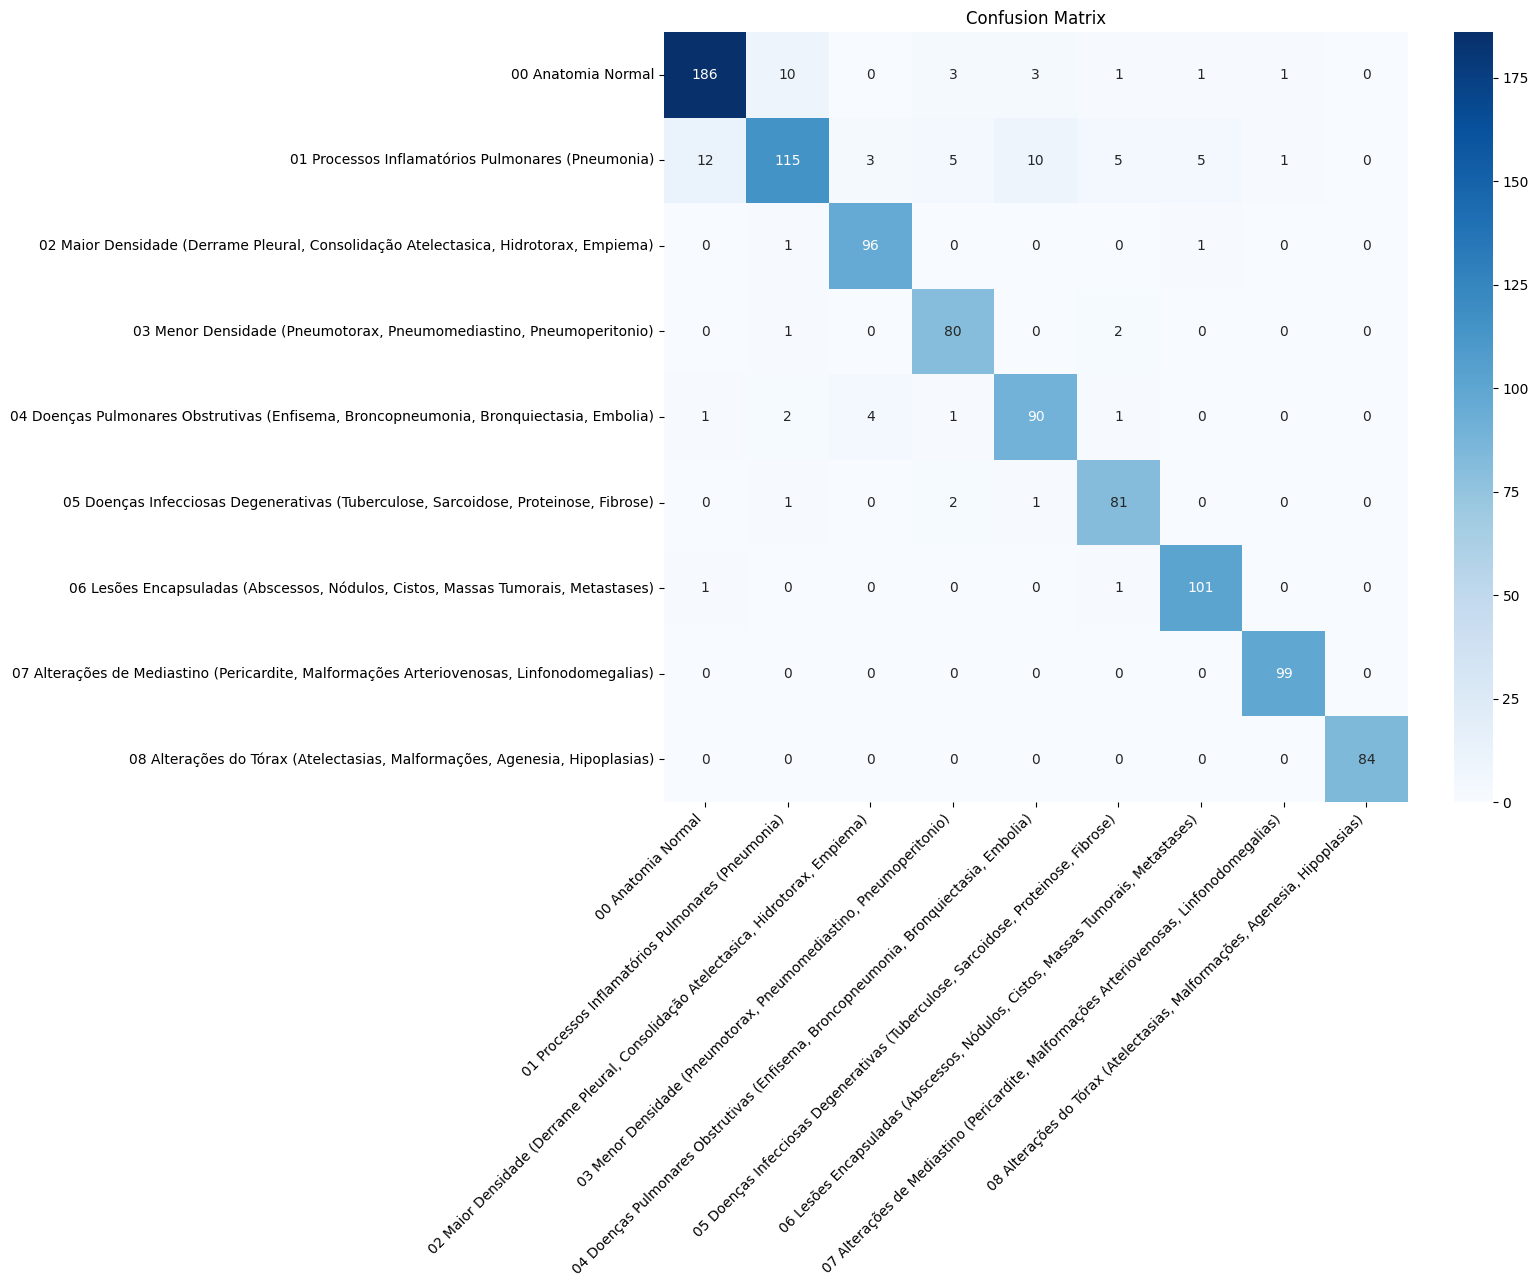

In [46]:
evaluate_model(classifier_densenet, X_test_dense, y_test_dense, device, class_names=full_dataset.class_names)

-------------------------------------------------------------------------------------------

In [47]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

def get_final_metrics(classifier, X_test, y_test, device, average='macro', verbose=True):
    """
    Evaluate the model and return accuracy, precision, and recall.
    
    Parameters:
    - classifier: Trained PyTorch model.
    - X_test (Tensor): Test features.
    - y_test (Tensor): Ground truth labels.
    - device (str): 'cuda' or 'cpu'.
    - average (str): Averaging method for precision and recall ('macro', 'micro', etc.).
    - verbose (bool): Whether to print the results.

    Returns:
    - (accuracy, precision, recall): tuple of float metrics.
    """
    classifier.eval()
    X_test, y_test = X_test.to(device), y_test.to(device)
    
    with torch.no_grad():
        outputs = classifier(X_test)
        preds = outputs.argmax(dim=1)

    # Convert tensors to CPU numpy arrays
    y_true = y_test.cpu().numpy()
    y_pred = preds.cpu().numpy()

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average=average, zero_division=0)
    recall = recall_score(y_true, y_pred, average=average, zero_division=0)

    if verbose:
        print(f"✅ Accuracy:  {accuracy:.4f}")
        print(f"✅ Precision: {precision:.4f} (avg: {average})")
        print(f"✅ Recall:    {recall:.4f} (avg: {average})")

    return accuracy, precision, recall

In [48]:
acc, prec, rec = get_final_metrics(classifier_vgg, X_test_vgg, y_test_vgg, device, average='macro')

✅ Accuracy:  0.9130
✅ Precision: 0.9191 (avg: macro)
✅ Recall:    0.9306 (avg: macro)


In [49]:
acc, prec, rec = get_final_metrics(classifier_resnet, X_test_resnet, y_test_resnet, device, average='macro')

✅ Accuracy:  0.9318
✅ Precision: 0.9349 (avg: macro)
✅ Recall:    0.9449 (avg: macro)


In [50]:
acc, prec, rec = get_final_metrics(classifier_densenet, X_test_dense, y_test_dense, device, average='macro')

✅ Accuracy:  0.9209
✅ Precision: 0.9219 (avg: macro)
✅ Recall:    0.9367 (avg: macro)


-------------------------------------------------------------------------------------------

In [51]:
import cv2
import numpy as np
from PIL import Image
import torch
from torchvision import transforms

def predict_xray_image(
    image_path,
    extractor,
    classifier,
    class_names,
    device='cuda' if torch.cuda.is_available() else 'cpu',
    enhance=True
):
    # 1. Load grayscale
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    if enhance:
        # CLAHE
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        img = clahe.apply(img)

        # Sharpen
        kernel = np.array([[0, -1, 0], 
                           [-1, 5, -1], 
                           [0, -1, 0]])
        img = cv2.filter2D(img, -1, kernel)

        # Add Gaussian noise
        noise = np.random.normal(0, 5, img.shape).astype(np.uint8)
        img = cv2.add(img, noise)

        # Clip just in case
        img = np.clip(img, 0, 255)

    # Convert to PIL
    img = Image.fromarray(img)

    # 2. Apply validation/test transform (no randomness!)
    transform_validation = transforms.Compose([
        transforms.Grayscale(num_output_channels=3),
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.5]*3, [0.5]*3)
    ])
    img_tensor = transform_validation(img).unsqueeze(0).to(device)  # [1, 3, 224, 224]

    # 3. Extract features
    extractor.eval()
    classifier.eval()
    with torch.no_grad():
        features = extractor(img_tensor)
        logits = classifier(features)
        pred_idx = logits.argmax(dim=1).item()
        pred_class = class_names[pred_idx]

    return pred_class


In [52]:
image_path = "/kaggle/input/mineee/My Scan.png"

predicted = predict_xray_image(
    image_path,
    extractor=extractor_vgg,
    classifier=classifier_vgg,
    class_names=full_dataset.class_names
)

print(f"🩻 Predicted class: {predicted}")

predicted = predict_xray_image(
    image_path,
    extractor=extractor_resnet,
    classifier=classifier_resnet,
    class_names=full_dataset.class_names
)

print(f"🩻 Predicted class: {predicted}")

predicted = predict_xray_image(
    image_path,
    extractor=extractor_densenet,
    classifier=classifier_densenet,
    class_names=full_dataset.class_names
)

print(f"🩻 Predicted class: {predicted}")


🩻 Predicted class: 02 Maior Densidade (Derrame Pleural, Consolidação Atelectasica, Hidrotorax, Empiema)
🩻 Predicted class: 01 Processos Inflamatórios Pulmonares (Pneumonia)
🩻 Predicted class: 03 Menor Densidade (Pneumotorax, Pneumomediastino, Pneumoperitonio)


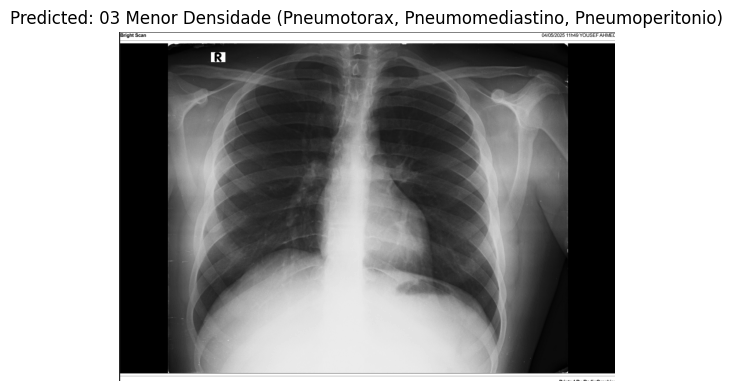

In [53]:
from matplotlib import pyplot as plt

plt.imshow(Image.open(image_path).convert("L"), cmap='gray')
plt.title(f"Predicted: {predicted}")
plt.axis('off')
plt.show()


In [ ]:
# Save the VGG feature extractor and classifier
torch.save(extractor_vgg.state_dict(), 'extractor_vgg.pth')
torch.save(classifier_vgg.state_dict(), 'classifier_vgg.pth')

# Save the class names
import json
with open('class_names.json', 'w') as f:
    json.dump(full_dataset.class_names, f)


In [ ]:
torch.save(extractor_resnet.state_dict(), 'extractor_resnet.pth')
torch.save(classifier_resnet.state_dict(), 'classifier_resnet.pth')

In [ ]:
torch.save(extractor_densenet.state_dict(), 'extractor_densenet.pth')
torch.save(classifier_densenet.state_dict(), 'classifier_densenet.pth')

-------------------------------------------------------------------------------------------

In [ ]:
!rm -rf /kaggle/working/*